In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
import pandas as pd
import numpy as np

# 1. Read data

In [3]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
DATA_PATH_IMMUNOGENIC = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows

# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

TARGET_PATH_TO_RESULTS = "experiment_results/"
# TARGET_PATH_TO_RESULTS = "experiment_results/backup/"


In [4]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")



per_allele_per_kfold_per_length_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "immunogenic")
per_allele_per_kfold_per_length_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "immunogenic")
per_allele_per_kfold_per_length_non_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "nonimmunogenic")
per_allele_per_kfold_per_length_non_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "nonimmunogenic")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [5]:
from hmm_logic_methods import load_model, get_model_representation, get_all_paths_with_probs

In [6]:
split_num = 3
run_num = 1
target_length = 9
states= 18
selected_binding = f"{run_num}_run-{target_length}-{states}-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-{split_num}"
selected_immunogenic = f"{run_num}_run_imm-{target_length}-mer-of-[{selected_binding}]_model-HLA_A_02_01-{split_num}"

MODEL_PATH_USED_IMMUNOGENIC = f"{TARGET_PATH_TO_RESULTS}{selected_immunogenic}/"
MODEL_PATH_USED_BINNDING = f"{TARGET_PATH_TO_RESULTS}{selected_binding}/"

model_immunogenic = load_model(TARGET_PATH_TO_RESULTS, selected_immunogenic)
model_binding = load_model(TARGET_PATH_TO_RESULTS, selected_binding)

train_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_train[ALLELES[0]][split_num][target_length]
train_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_train[ALLELES[0]][split_num][target_length]

train_peptides_binding = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][split_num][target_length]
train_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_train[ALLELES[0]][split_num][target_length]


test_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_binding = per_allele_per_kfold_per_length_binders_test[ALLELES[0]][split_num][target_length]
test_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_test[ALLELES[0]][split_num][target_length]


# 3. Working with paths
## 3.1 Generate most probable paths, with probs

In [7]:
df_b_paths, edge_to_prob_b = get_all_paths_with_probs(model_binding)
df_i_paths, edge_to_prob_i = get_all_paths_with_probs(model_immunogenic)

Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3) (Delete zero edges)
found 38 paths
Converting graph for model (1_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3]_model-HLA_A_02_01-3) (Delete zero edges)
found 6 paths


## 3.2 Get representation DF for different data

In [8]:
generated_peptides_b = ["".join(model_binding.sample()) for i in range(2000)]
generated_peptides_i = ["".join(model_immunogenic.sample()) for i in range(2000)]

In [9]:
%%time
print("Train")
train_peptides_repr_data_b_model_b, path_to_index1 = get_model_representation(model_binding, set(train_peptides_binding), edge_value="log_probability")
train_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(train_peptides_binding), edge_value="log_probability")
train_peptides_repr_data_i_model_b, path_to_index2 = get_model_representation(model_binding, set(train_peptides_immunogenic), edge_value="log_probability")
train_peptides_repr_data_i_model_i,_ = get_model_representation(model_immunogenic, set(train_peptides_immunogenic), edge_value="log_probability")

print("Test")
test_peptides_repr_data_b_model_b, path_to_index3 = get_model_representation(model_binding, set(test_peptides_binding), edge_value="log_probability")
test_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(test_peptides_binding), edge_value="log_probability")
test_peptides_repr_data_i_model_b, path_to_index4 = get_model_representation(model_binding, set(test_peptides_immunogenic), edge_value="log_probability")
test_peptides_repr_data_i_model_i, _ = get_model_representation(model_immunogenic, set(test_peptides_immunogenic), edge_value="log_probability")

print("Generated")
generated_peptides_repr_data_b_model_b, _ = get_model_representation(model_binding, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_repr_data_i_model_b, _ = get_model_representation(model_binding, set(generated_peptides_i), edge_value="log_probability")
generated_peptides_repr_data_i_model_i, _ = get_model_representation(model_immunogenic, set(generated_peptides_i), edge_value="log_probability")


#make dict for convinience
pivot_data_dict = dict()

dataset_keys = ['Train', 'Test', 'Generated']
source_keys = ['db', 'di']
model_keys = ['mb', 'mi']
for key in dataset_keys:
    pivot_data_dict[key] = dict()
    for s_key in source_keys:
        pivot_data_dict[key][s_key] = dict()
        
        
pivot_data_dict['Train']['db']['mb'] = train_peptides_repr_data_b_model_b
pivot_data_dict['Train']['db']['mi'] = train_peptides_repr_data_b_model_i
pivot_data_dict['Train']['di']['mb'] = train_peptides_repr_data_i_model_b
pivot_data_dict['Train']['di']['mi'] = train_peptides_repr_data_i_model_i

pivot_data_dict['Test']['db']['mb'] = test_peptides_repr_data_b_model_b
pivot_data_dict['Test']['db']['mi'] = test_peptides_repr_data_b_model_i
pivot_data_dict['Test']['di']['mb'] = test_peptides_repr_data_i_model_b
pivot_data_dict['Test']['di']['mi'] = test_peptides_repr_data_i_model_i

pivot_data_dict['Generated']['db']['mb'] = generated_peptides_repr_data_b_model_b
pivot_data_dict['Generated']['db']['mi'] = generated_peptides_repr_data_b_model_i
pivot_data_dict['Generated']['di']['mb'] = generated_peptides_repr_data_i_model_b
pivot_data_dict['Generated']['di']['mi'] = generated_peptides_repr_data_i_model_i



Train
Model 1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3
	Find all paths
Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3) (Delete zero edges)
found 38 paths
	Calculate probs for peptides
Model 1_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3]_model-HLA_A_02_01-3
	Find all paths
Converting graph for model (1_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3]_model-HLA_A_02_01-3) (Delete zero edges)
found 6 paths
	Calculate probs for peptides


D:\Projects\MHC_predictor\experiments\length_dependent_hmm\hmm_logic_methods.py:294: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


Model 1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3
	Find all paths
Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3) (Delete zero edges)
found 38 paths
	Calculate probs for peptides
Model 1_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3]_model-HLA_A_02_01-3
	Find all paths
Converting graph for model (1_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3]_model-HLA_A_02_01-3) (Delete zero edges)
found 6 paths
	Calculate probs for peptides
Test
Model 1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3
	Find all paths
Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3) (Delete zero edges)
found 38 paths
	Calculate probs for peptides
Model 1_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-3]_model-HLA_A_02_01-3
	Find all paths
Converting graph for model (1_run_imm-9-mer-of-[1_run-9-18-st-baum-we

## 3.3 Save embedding to files for analysis

In [10]:
pd.DataFrame(path_to_index1.items()).to_csv('train_db_mb_path_indexes_BvsIofB.csv')

In [11]:
train_peptides_repr_data_b_model_b.to_csv('train_db_mb_representation_BvsIofB.csv')

In [12]:
sample_pivot = pivot_data_dict['Train']['di']['mb']

sample_pivot.head()

path_index,0,1,2,3,4,5,6,7,8,9,...,28,29,30,31,32,33,34,35,36,37
peptide,,,,,,,,,,,,,,,,,,,,,
AIISGDSPV,-39.606898,-47.915536,-43.890234,-35.689617,-40.586512,-48.895150,-26.402720,-34.711358,-40.647864,-48.956502,...,-36.656719,-44.965357,-40.391587,-48.700225,-44.674923,-36.474306,-41.371201,-49.679839,-27.187409,-35.496047
AIMDKNIIL,-32.722296,-41.984024,-36.612520,-29.364993,-33.216448,-42.478176,-27.285165,-36.546893,-33.490920,-42.752648,...,-28.151781,-37.413509,-33.506985,-42.768712,-37.397209,-30.149682,-34.001137,-43.262865,-28.069854,-37.331582
AINGVMWTV,-36.274550,-44.583188,-38.160011,-29.959394,-36.069356,-44.377994,-29.394691,-37.703328,-37.547915,-45.856553,...,-32.234558,-40.543196,-37.059239,-45.367877,-38.944700,-30.744083,-36.854045,-45.162683,-30.179379,-38.488017
AIYDTMQYV,-77.408712,-85.717350,-78.994566,-70.793949,-77.729557,-86.038194,-30.470138,-38.778776,-78.120327,-86.428965,...,-72.607880,-80.916518,-78.193401,-86.502039,-79.779255,-71.578638,-78.514245,-86.822883,-31.254827,-39.563465
ALAEGDLLA,-41.725440,-50.442921,-45.348392,-37.556619,-42.661226,-51.378708,-28.521261,-37.238743,-38.137826,-46.855308,...,-33.447425,-42.164906,-37.780672,-46.498153,-41.403624,-33.611851,-38.716458,-47.433940,-24.576493,-33.293975


In [13]:
train_pivot = train_peptides_repr_data_b_model_b
test_pivot = test_peptides_repr_data_b_model_b
train_pivot_plus = train_pivot.copy()
train_pivot_plus['dataset'] = "Train"
test_pivot_plus = test_pivot.copy()
test_pivot_plus['dataset'] = "Test"

total_pivot_plus = pd.concat([train_pivot_plus, test_pivot_plus])

In [14]:
for i in range(9):
    total_pivot_plus[f'a{i}'] = total_pivot_plus.index.str[i]

In [15]:
aa_columns = [f"a{i}" for i in range(9)]
total_pivot_plus[['dataset'] + aa_columns + [col for col in total_pivot_plus.columns if col != 'dataset' and col not in aa_columns]].to_csv(f'embedding_for_phantasus_B_BvsIofB.csv',sep="\t", index=True)

In [16]:
type(total_pivot_plus.loc['SPPLPPAPP'][1])

numpy.float64

# 4. Compare models
## 4.1 Transitions

In [18]:
transition_b= model_binding.dense_transition_matrix()
transition_b_df= pd.DataFrame(transition_b, columns=[state.name for state in model_binding.states], index=[state.name for state in model_binding.states])
transition_i= model_immunogenic.dense_transition_matrix()
transition_i_df= pd.DataFrame(transition_i, columns=[state.name for state in model_immunogenic.states], index=[state.name for state in model_immunogenic.states])
diff_df = np.abs(transition_b_df - transition_i_df)
diff2_df = transition_i_df - transition_b_df

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
from collections import defaultdict
from hmm_visualization_methods import make_levels

Text(0.5, 1.0, 'Binding model')

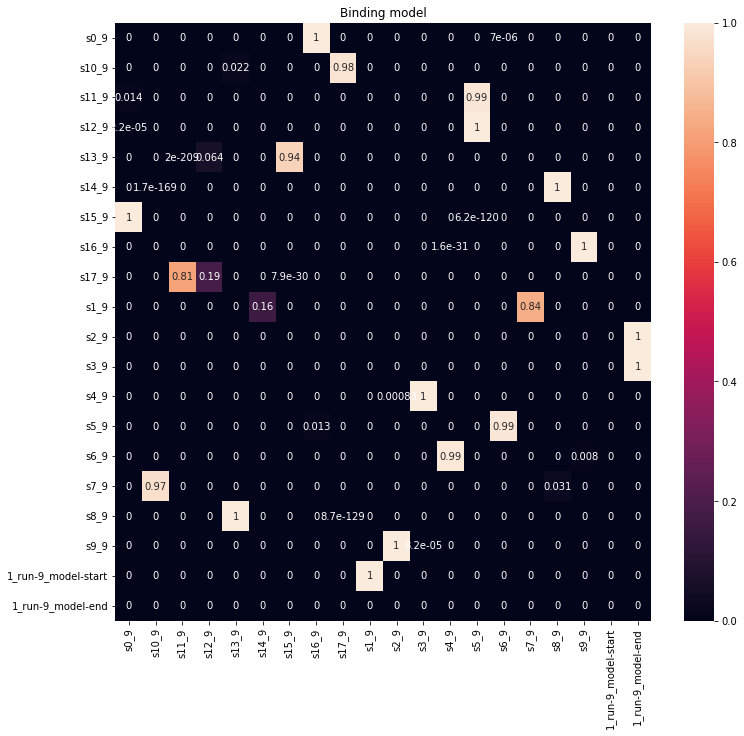

In [20]:
plt.figure(figsize=(12, 11))
ax = sns.heatmap(transition_b_df, annot=True)
ax.set_title("Binding model")

Text(0.5, 1.0, 'Immunogenicity model')

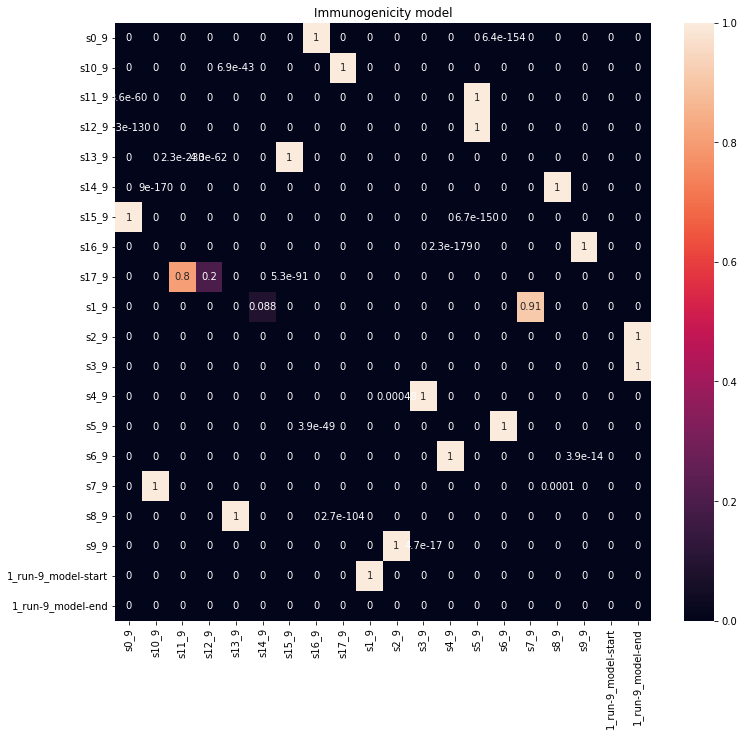

In [21]:
plt.figure(figsize=(12, 11))
ax = sns.heatmap(transition_i_df, annot=True)
ax.set_title("Immunogenicity model")

<AxesSubplot:>

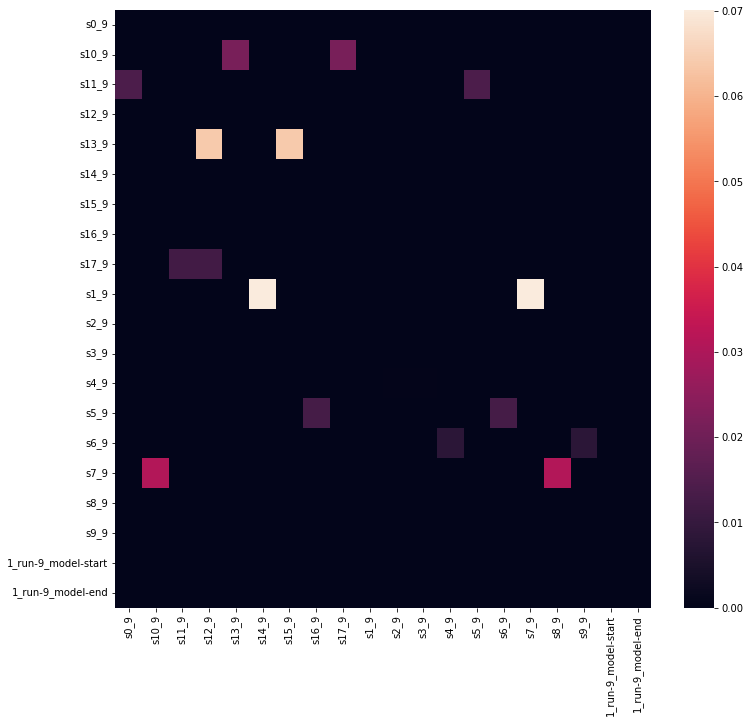

In [22]:
plt.figure(figsize=(12, 11))
sns.heatmap(diff_df)

<AxesSubplot:>

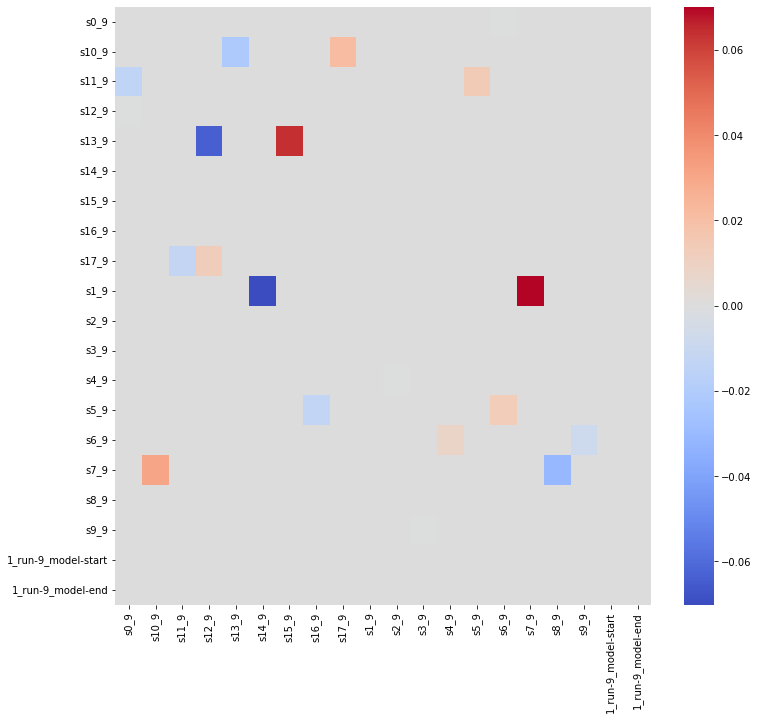

In [23]:
plt.figure(figsize=(12, 11))
sns.heatmap(diff2_df, cmap="coolwarm")

In [24]:
hottest_areas = np.ma.MaskedArray(diff2_df, np.abs(diff2_df) < 0)
X, Y = hottest_areas.nonzero()

hottest_points = [(x,y, value) for x, y , value in zip(X, Y, [hottest_areas[i,j] for i,j in zip(X,Y)])]
sorted_hottest_points = list(sorted(hottest_points, key=lambda x:np.abs(x[2]), reverse=True))
#print state_names
states_b = model_binding.states
name_to_change = defaultdict(int)
name_to_level = make_levels(model_binding)
transition_to_change = defaultdict(int)
for x,y, value in sorted_hottest_points:
    print(f"{states_b[x].name} -> {states_b[y].name} : {value}")
    name_to_change[states_b[x].name] += value
    # position is level - 2
    transition_to_change[f"{name_to_level[states_b[x].name] - 2}->{name_to_level[states_b[y].name] - 2}"] += np.abs(value)


s1_9 -> s14_9 : -0.0701377096165422
s1_9 -> s7_9 : 0.0701377096165422
s13_9 -> s12_9 : -0.06400702526197614
s13_9 -> s15_9 : 0.0640070252619761
s7_9 -> s8_9 : -0.030899499380742237
s7_9 -> s10_9 : 0.030899499380742212
s10_9 -> s13_9 : -0.021535649259862292
s10_9 -> s17_9 : 0.02153564925986229
s11_9 -> s5_9 : 0.014186301577832627
s11_9 -> s0_9 : -0.014186301577832593
s5_9 -> s16_9 : -0.012639568310031258
s5_9 -> s6_9 : 0.012639568310031213
s17_9 -> s11_9 : -0.012198017130070626
s17_9 -> s12_9 : 0.012198017130070515
s6_9 -> s4_9 : 0.008015933716091106
s6_9 -> s9_9 : -0.008015933716091057
s4_9 -> s2_9 : -0.00035162870013197815
s4_9 -> s3_9 : 0.00035162870013194514
s9_9 -> s2_9 : 8.15078230907984e-05
s9_9 -> s3_9 : -8.150782309062803e-05
s12_9 -> s5_9 : 2.2392228266721048e-05
s12_9 -> s0_9 : -2.2392228266709776e-05
s0_9 -> s16_9 : 6.96318989845679e-06
s0_9 -> s6_9 : -6.963189898329918e-06
s17_9 -> s15_9 : -7.859185360832225e-30
s16_9 -> s4_9 : -1.6495631290056532e-31
s8_9 -> s17_9 : 2.6813

In [25]:
for position, value in sorted(transition_to_change.items()):
    print(position, value)

0->1 0.1402754192330844
1->2 0.06179899876148445
2->3 0.04307129851972458
3->4 0.1524100847840934
4->5 0.02841738761219865
5->6 0.025293062999859256
6->7 0.016031867432182163
7->8 0.0008662730464453497


## 4.2 Emissions

In [26]:
def get_emission_matrix(model):
    states_list = model.states
    emission_matrix = np.zeros(shape=(len(states_list), 20))
    for i,state in enumerate(states_list):
        if state.distribution is not None:
            amino_acids = list(state.distribution.parameters[0].keys())
            emission_matrix[i, :] = list(state.distribution.parameters[0].values())
    emissions_df = pd.DataFrame(emission_matrix, columns=amino_acids, index=[state.name for state in states_list])
    return emissions_df

def get_per_position_emission_df(model, emission_matrix_df):
    # We want to get per position pictures
    name_to_level = make_levels(model)
    per_position_rows = defaultdict(list)
    per_position_df = dict()
    for state_name in emission_matrix_df.index.values:
        position = name_to_level[state_name] - 2
        per_position_rows[position].append(emission_matrix_df.loc[state_name].copy())
    for position, rows in sorted(per_position_rows.items()):
        df = pd.DataFrame(rows)
        per_position_df[position] = df
    return per_position_df
    
    

    
    
emission_df_b = get_emission_matrix(model_binding)
    
emission_df_i = get_emission_matrix(model_immunogenic)


emission_df_b.head()


,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
s0_9,0.075002,4.233775e-03,0.029823,3.661625e-02,0.043833,0.073370,0.021164,0.066264,0.050664,0.121445,1.204051e-02,0.031411,0.075670,4.095310e-02,5.601164e-02,7.674218e-02,7.494881e-02,0.079874,1.037211e-02,1.956105e-02
s10_9,0.100412,5.967036e-03,0.084925,2.192211e-02,0.057655,0.035734,0.027434,0.072404,0.020875,0.152147,4.201619e-02,0.040533,0.031753,4.910599e-02,1.092945e-02,7.517895e-02,4.212482e-02,0.047698,2.848382e-02,5.270224e-02
s11_9,0.081076,1.110052e-02,0.040271,8.330512e-02,0.031849,0.076759,0.032952,0.076969,0.050934,0.103200,1.627735e-02,0.027109,0.011913,5.392511e-02,4.127195e-08,7.231267e-02,7.473681e-02,0.085621,1.539809e-02,5.429110e-02
s12_9,0.000008,4.107590e-36,0.070702,3.805084e-30,0.135699,0.000158,0.080781,0.016890,0.163724,0.064184,3.958147e-22,0.094974,0.056404,2.586472e-36,2.499104e-01,2.256794e-19,1.543688e-19,0.066566,3.450854e-25,3.322577e-13
s13_9,0.080269,5.810965e-03,0.054737,7.925558e-02,0.035500,0.065676,0.013020,0.064137,0.043901,0.117038,1.666612e-02,0.023752,0.115505,3.742555e-02,2.757543e-02,7.533423e-02,4.570189e-02,0.068653,8.438537e-03,2.160447e-02


<AxesSubplot:>

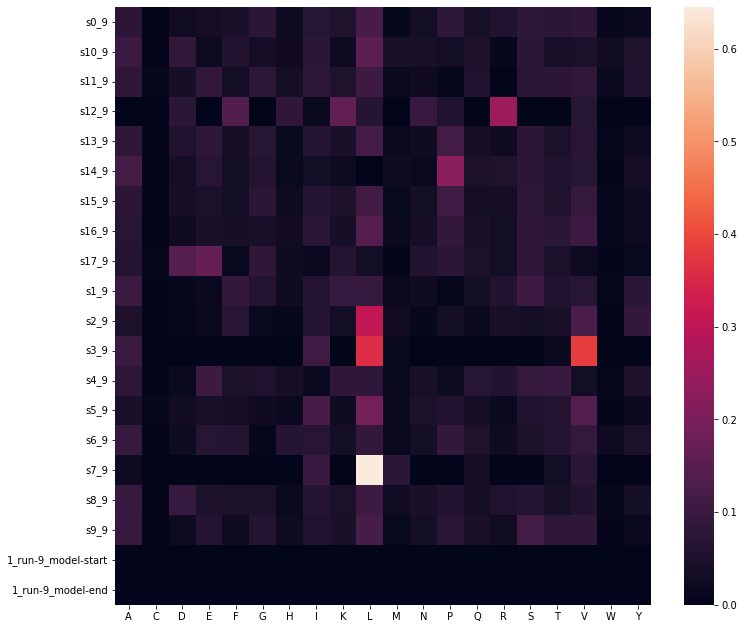

In [27]:
#heatmap
plt.figure(figsize=(12, 11))
sns.heatmap(emission_df_b)

<AxesSubplot:>

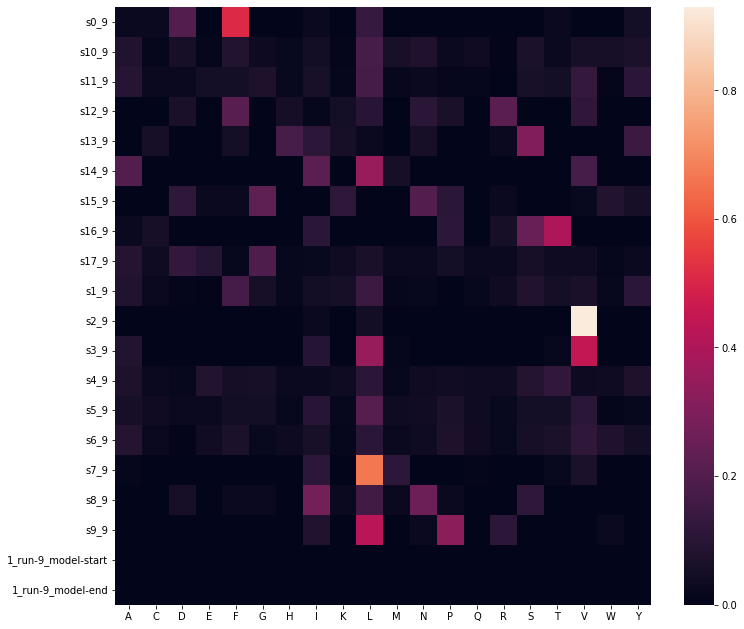

In [28]:
#heatmap
plt.figure(figsize=(12, 11))
sns.heatmap(emission_df_i)

In [29]:
per_position_emission_b_df = get_per_position_emission_df(model_binding, emission_df_b)

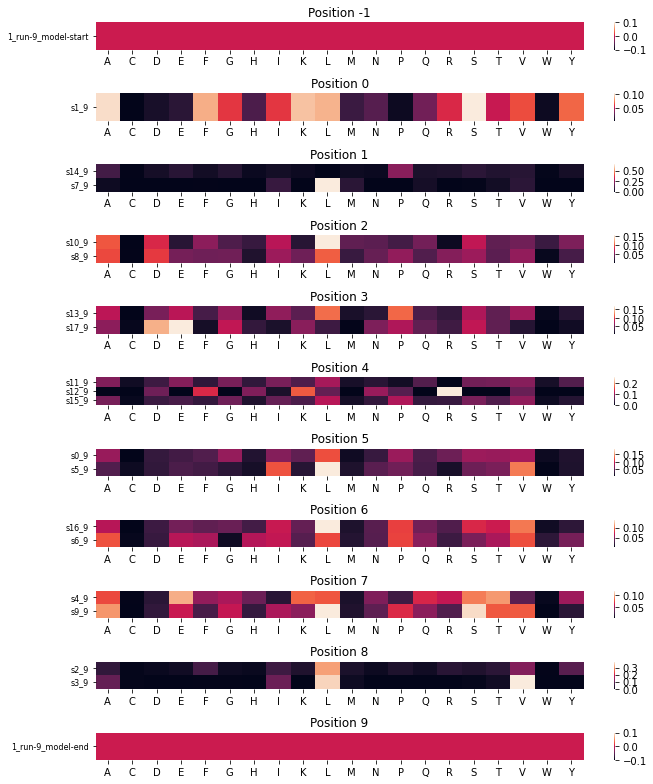

In [30]:
fig, axes = plt.subplots(nrows=len(per_position_emission_b_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_b_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()


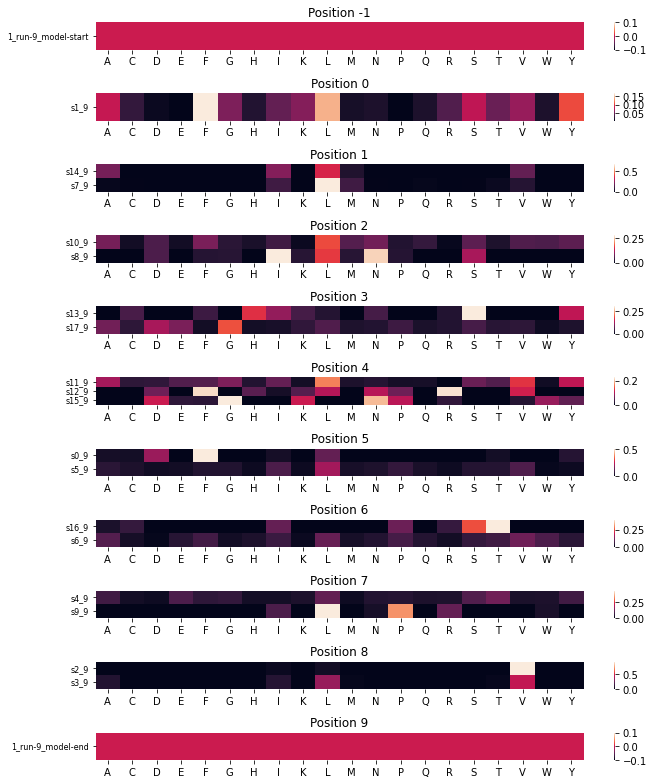

In [31]:
per_position_emission_i_df = get_per_position_emission_df(model_immunogenic, emission_df_i)
fig, axes = plt.subplots(nrows=len(per_position_emission_i_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_i_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()


## Diference

<AxesSubplot:>

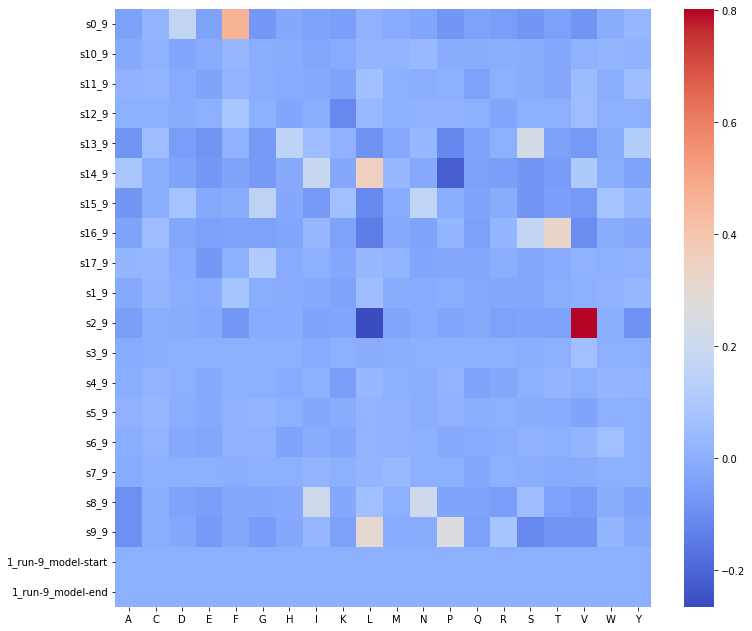

In [32]:
diff_df =  emission_df_i - emission_df_b
plt.figure(figsize=(12, 11))
sns.heatmap(diff_df, cmap="coolwarm")

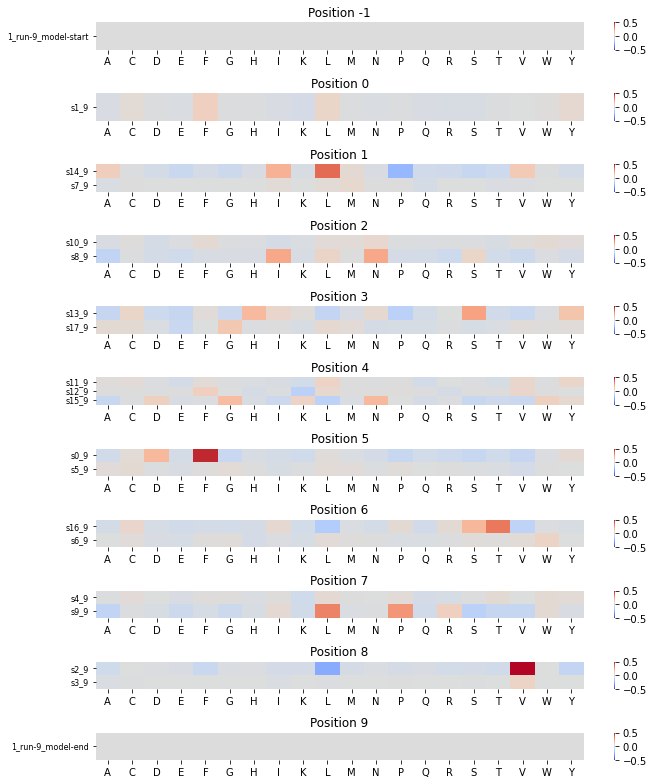

In [33]:
per_position_emission_diff_df = get_per_position_emission_df(model_binding, diff_df)
fig, axes = plt.subplots(nrows=len(per_position_emission_diff_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_diff_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax, cmap='coolwarm', vmin=-0.5, vmax=0.5)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()

In [34]:
per_position_emission_b_df[2].sum().values.reshape(1,-1)

array([[0.19701939, 0.01259195, 0.17689115, 0.07137137, 0.10489032,
        0.08361323, 0.04593993, 0.13538132, 0.06848275, 0.25515637,
        0.06984902, 0.08501205, 0.09103664, 0.08596264, 0.06576533,
        0.13814578, 0.08244817, 0.10690599, 0.03785739, 0.08567921]])

In [35]:
df = pd.DataFrame(per_position_emission_b_df[2].sum().values.reshape(1,-1), columns = per_position_emission_b_df[2].columns )

In [36]:
per_position_emission_b_df[2]

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
s10_9,0.100412,0.005967,0.084925,0.021922,0.057655,0.035734,0.027434,0.072404,0.020875,0.152147,0.042016,0.040533,0.031753,0.049106,0.010929,0.075179,0.042125,0.047698,0.028484,0.052702
s8_9,0.096608,0.006625,0.091967,0.049449,0.047236,0.047879,0.018506,0.062977,0.047607,0.103009,0.027833,0.044479,0.059284,0.036857,0.054836,0.062967,0.040323,0.059208,0.009374,0.032977


In [37]:
df

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.197019,0.012592,0.176891,0.071371,0.10489,0.083613,0.04594,0.135381,0.068483,0.255156,0.069849,0.085012,0.091037,0.085963,0.065765,0.138146,0.082448,0.106906,0.037857,0.085679


<AxesSubplot:>

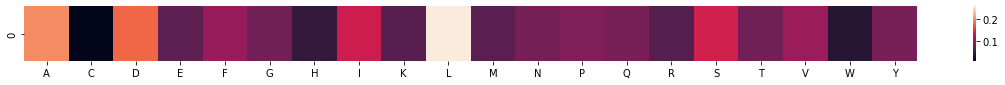

In [38]:
plt.figure(figsize=(20,1))
sns.heatmap(df)

In [39]:
import scipy
positions = list()
states = list()
state_entropies = list()
position_entropies = list()

for i, (position, df) in enumerate(sorted(per_position_emission_b_df.items())):
    df_b = df
    df_i = per_position_emission_i_df[position]
    
    sum_row_b = df_b.sum()
    sum_row_i = df_i.sum()
    sum_entropy =  scipy.stats.entropy(sum_row_i.values, sum_row_b.values)
    print(f"Position {position}")
    print(f"Position entropy: {np.round(sum_entropy,3)}")
    for (name_b, row_b), (name_i, row_i) in zip(df_b.iterrows(),df_i.iterrows()):
        assert name_b == name_i
        entropy = scipy.stats.entropy(row_i.values, row_b.values)
        if entropy ==  np.inf:
            print(f" b : {row_b.values}")
            print(f" i : {row_i.values}")
        print(f"{name_b} change -> {np.round(entropy,3)}")
        positions.append(position)
        states.append(name_b)
        state_entropies.append(np.round(entropy,3))
        position_entropies.append(np.round(sum_entropy,3))
        

result = pd.DataFrame({"position": positions, "state": states, "state entropy": state_entropies, "position entropy": position_entropies})
    

Position -1
Position entropy: nan
1_run-9_model-start change -> nan
Position 0
Position entropy: 0.116
s1_9 change -> 0.116
Position 1
Position entropy: 0.507
s14_9 change -> 2.555
s7_9 change -> 0.047
Position 2
Position entropy: 0.28
s10_9 change -> 0.073
s8_9 change -> 0.9
Position 3
Position entropy: 0.368
s13_9 change -> 1.357
s17_9 change -> 0.173
Position 4
Position entropy: 0.155
s11_9 change -> 0.126
s12_9 change -> 0.108
s15_9 change -> 0.996
Position 5
Position entropy: 0.52
s0_9 change -> 1.653
s5_9 change -> 0.049
Position 6
Position entropy: 0.354
s16_9 change -> 1.175
s6_9 change -> 0.113
Position 7
Position entropy: 0.391
s4_9 change -> 0.094
s9_9 change -> 1.274
Position 8
Position entropy: 0.512
s2_9 change -> 1.742
s3_9 change -> 0.026
Position 9
Position entropy: nan
1_run-9_model-end change -> nan


d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\scipy\stats\_entropy.py:72: RuntimeWarning: invalid value encountered in true_divide
  pk = 1.0*pk / np.sum(pk, axis=axis, keepdims=True)
d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\scipy\stats\_entropy.py:78: RuntimeWarning: invalid value encountered in true_divide
  qk = 1.0*qk / np.sum(qk, axis=axis, keepdims=True)


In [40]:
result

,position,state,state entropy,position entropy
0,-1,1_run-9_model-start,NaN,NaN
1,0,s1_9,0.116,0.116
2,1,s14_9,2.555,0.507
3,1,s7_9,0.047,0.507
4,2,s10_9,0.073,0.280
5,2,s8_9,0.900,0.280
6,3,s13_9,1.357,0.368
7,3,s17_9,0.173,0.368
8,4,s11_9,0.126,0.155
9,4,s12_9,0.108,0.155


In [41]:
result[['position', 'position entropy']].drop_duplicates()

,position,position entropy
0,-1,NaN
1,0,0.116
2,1,0.507
4,2,0.280
6,3,0.368
8,4,0.155
11,5,0.520
13,6,0.354
15,7,0.391
17,8,0.512


In [42]:
result[['position','state' ,'state entropy']]

,position,state,state entropy
0,-1,1_run-9_model-start,NaN
1,0,s1_9,0.116
2,1,s14_9,2.555
3,1,s7_9,0.047
4,2,s10_9,0.073
5,2,s8_9,0.900
6,3,s13_9,1.357
7,3,s17_9,0.173
8,4,s11_9,0.126
9,4,s12_9,0.108


In [43]:
# We want to get per position pictures
name_to_level = make_levels(model_binding)

per_position_rows = defaultdict(list)
for state_name in diff_df.index.values:

    position = name_to_level[state_name] - 2
    per_position_rows[position].append(diff_df.loc[state_name].copy())

# Evaluare paths

## Model binding
### Generated_data

In [44]:
generated_df_repr_db = pivot_data_dict['Generated']['db']['mb']
generated_df_repr_di = pivot_data_dict['Generated']['di']['mb']

In [45]:
def get_path_changes(df_b, df_i, paths_df):
    path_index_to_score_db = defaultdict(int)
    for index, row in df_b.iterrows():
        for path_index, column_value in enumerate(row):
            path_index_to_score_db[path_index] += column_value
            # if column_value > treshold:
            #     path_index_to_score_db[path_index] += 1

    path_index_to_score_di = defaultdict(int)
    for index, row in df_i.iterrows():
        for path_index, column_value in enumerate(row):
            path_index_to_score_di[path_index] += column_value
            # if column_value > treshold:
            #     path_index_to_score_di[path_index] += 1
                
    #normalize by size of sample

    for path_index in path_index_to_score_db:
        path_index_to_score_db[path_index] = path_index_to_score_db[path_index] / len(df_b)


    for path_index in path_index_to_score_di:
        path_index_to_score_di[path_index] = path_index_to_score_di[path_index] / len(df_i)
    dfb = pd.DataFrame.from_dict(path_index_to_score_db, orient='index', columns=["value"])
    dfi = pd.DataFrame.from_dict(path_index_to_score_di, orient='index', columns=["value"])
    merge_df = pd.merge(dfb, dfi, left_index=True, right_index=True, suffixes=['_b','_i'])
    merge_df['diff'] = merge_df['value_i'].subtract(merge_df['value_b'], fill_value=0)
    
    paths_df_copy = paths_df.copy()
    paths_df_copy[['start'] +  [f'state_{i}' for i in range(target_length)] + ['end'] ] = pd.DataFrame(paths_df_copy['path'].to_list(), index=paths_df_copy.index)
    paths_df_copy= paths_df_copy.drop(columns=['start', 'end', 'path'])
    

    total_df = pd.merge(merge_df, paths_df_copy,  left_index=True, right_index=True, suffixes=['_b','_i'])
    return total_df

In [46]:
total_df = get_path_changes(generated_df_repr_db, generated_df_repr_di, df_b_paths).sort_values('diff')
total_df.to_csv("generated_paths_changes.csv")

In [47]:
total_df

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
6,-28.725133,-29.483700,-0.758567,-3.711744,s1_9,s7_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s2_9
2,-54.315505,-52.595626,1.719879,-11.233419,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s9_9,s2_9
0,-51.715115,-49.931535,1.783580,-13.510416,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s4_9,s2_9
4,-52.129821,-50.339649,1.790172,-10.765298,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s16_9,s9_9,s2_9
7,-42.744903,-38.228809,4.516094,-13.126474,s1_9,s7_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s3_9
3,-51.826021,-44.831481,6.994540,-20.648149,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s9_9,s3_9
1,-65.734885,-58.676645,7.058241,-6.415891,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s4_9,s3_9
5,-66.149592,-59.084759,7.064833,-20.180028,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s16_9,s9_9,s3_9
36,-56.231020,-27.382944,28.848076,-1.912616,s1_9,s14_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s2_9
14,-56.574619,-27.611176,28.963443,-4.107519,s1_9,s7_9,s10_9,s13_9,s15_9,s0_9,s16_9,s9_9,s2_9


### Train data

In [48]:
train_df_repr_db = pivot_data_dict['Train']['db']['mb']
train_df_repr_di = pivot_data_dict['Train']['di']['mb']

In [49]:
total_df = get_path_changes(train_df_repr_db, train_df_repr_di, df_b_paths).sort_values('diff')
total_df.to_csv("train_paths_changes.csv")

In [50]:
total_df.sort_values('diff')

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
6,-28.688442,-29.396589,-0.708147,-3.711744,s1_9,s7_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s2_9
2,-54.184817,-51.349041,2.835777,-11.233419,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s9_9,s2_9
0,-51.568604,-48.671036,2.897568,-13.510416,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s4_9,s2_9
4,-51.988040,-49.089764,2.898276,-10.765298,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s16_9,s9_9,s2_9
7,-42.728227,-38.143423,4.584804,-13.126474,s1_9,s7_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s3_9
3,-51.715347,-43.586619,8.128728,-20.648149,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s9_9,s3_9
1,-65.608388,-57.417869,8.190519,-6.415891,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s6_9,s4_9,s3_9
5,-66.027824,-57.836598,8.191227,-20.180028,s1_9,s7_9,s8_9,s13_9,s12_9,s5_9,s16_9,s9_9,s3_9
36,-55.920268,-27.345742,28.574526,-1.912616,s1_9,s14_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s2_9
20,-59.984371,-31.347926,28.636446,-5.284570,s1_9,s7_9,s10_9,s17_9,s11_9,s5_9,s6_9,s9_9,s2_9


## Model Immunogenic
### Generated data

In [51]:
generated_df_repr_db = pivot_data_dict['Generated']['db']['mi']
generated_df_repr_di = pivot_data_dict['Generated']['di']['mi']

In [52]:
total_df = get_path_changes(generated_df_repr_db, generated_df_repr_di, df_i_paths).sort_values('diff')
total_df.to_csv("generated_paths_changes_mi.csv")

In [53]:
df_i_paths['path'].values

array([list(['1_run-9_model-start', 's1_9', 's7_9', 's10_9', 's17_9', 's11_9', 's5_9', 's6_9', 's4_9', 's3_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's1_9', 's7_9', 's10_9', 's17_9', 's12_9', 's5_9', 's6_9', 's4_9', 's3_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's1_9', 's14_9', 's8_9', 's13_9', 's15_9', 's0_9', 's16_9', 's9_9', 's2_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's1_9', 's7_9', 's10_9', 's17_9', 's11_9', 's5_9', 's6_9', 's4_9', 's2_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's1_9', 's7_9', 's8_9', 's13_9', 's15_9', 's0_9', 's16_9', 's9_9', 's2_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's1_9', 's7_9', 's10_9', 's17_9', 's12_9', 's5_9', 's6_9', 's4_9', 's2_9', '1_run-9_model-end'])],
      dtype=object)

### Train data

In [54]:
train_df_repr_db = pivot_data_dict['Train']['db']['mi']
train_df_repr_di = pivot_data_dict['Train']['di']['mi']

In [55]:
total_df = get_path_changes(train_df_repr_db, train_df_repr_di, df_i_paths).sort_values('diff')
total_df.to_csv("train_paths_changes_mi.csv")

In [56]:
total_df.head()

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
5,-49121.551713,-43381.733549,5739.818164,-2.434179,s1_9,s14_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s2_9
0,-49201.109364,-43380.787909,5820.321456,-9.295273,s1_9,s7_9,s8_9,s13_9,s15_9,s0_9,s16_9,s9_9,s2_9
2,-8595.876796,-22.679017,8573.197778,-0.313584,s1_9,s7_9,s10_9,s17_9,s11_9,s5_9,s6_9,s4_9,s3_9
4,-8609.903069,-35.877757,8574.025312,-1.709369,s1_9,s7_9,s10_9,s17_9,s12_9,s5_9,s6_9,s4_9,s3_9
1,-13550.819921,-4420.687098,9130.132823,-7.960433,s1_9,s7_9,s10_9,s17_9,s11_9,s5_9,s6_9,s4_9,s2_9


In [57]:
train_df_repr_di

path_index,0,1,2,3,4,5
peptide,,,,,,
AIISGDSPV,-14.606244,-31.187948,-24.281422,-39.198001,-32.291475,-22.161033
AIMDKNIIL,-50000.000000,-34.881742,-25.152328,-34.839293,-25.109878,-50000.000000
AINGVMWTV,-50000.000000,-27.003719,-20.097194,-28.507698,-21.601172,-50000.000000
AIYDTMQYV,-50000.000000,-29.861455,-22.954929,-71.811720,-64.905194,-50000.000000
ALAEGDLLA,-50000.000000,-50000.000000,-21.464270,-50000.000000,-29.474323,-50000.000000
...,...,...,...,...,...,...
YMNSIRLYA,-50000.000000,-50000.000000,-24.332076,-50000.000000,-27.254593,-50000.000000
YSLEYFQFV,-50000.000000,-31.886157,-24.979631,-60.001532,-53.095006,-50000.000000
YTMDGEYRL,-50000.000000,-35.020863,-25.291449,-43.030916,-33.301502,-50000.000000


## Some statistics test with known answer

In [58]:
df = pd.read_csv('D:\\Sandbox\onesnp.csv', header=None, names=['acid', 'value'])
df.head()

,acid,value
0,C,1
1,G,0
2,G,0
3,T,1
4,G,0


In [59]:
from scipy.stats import chi2

def get_sz(a, b):
    return len(df[(df.acid.astype('str') == a) & (df["value"] == b)])

def xi(a, b):
    m1 = 0
    for i in ["A", "C", "G", "T"]:
        m1 += get_sz(i, b)
    m2 = get_sz(a, 0) + get_sz(a, 1)

    n = len(df)
    return (((get_sz(a, b) - m1 * m2 / n) ** 2) / (m1 * m2 / n))

def glob_xi():
    res = 0
    for i in [0, 1]:
        for j in ["A", "C", "G", "T"]:
            res += xi(j, i)
    return res

print("A:", get_sz('A', 1), get_sz('A', 0))
print("C:", get_sz('C', 1), get_sz('C', 0))
print("G:", get_sz('G', 1), get_sz('G', 0))
print("T:", get_sz('T', 1), get_sz('T', 0))

print("chi^2:", glob_xi())
print("p-value:", 1 - chi2.cdf(glob_xi(), 3))

A: 1199 1224
C: 1266 1259
G: 1253 1286
T: 1276 1237
chi^2: 1.2971142104271318
p-value: 0.7298184494688893


In [60]:
crosstab = pd.crosstab( df['value'],df['acid'])
crosstab

acid,A,C,G,T
value,,,,
0,1224,1259,1286,1237
1,1199,1266,1253,1276


## with statsmodels

In [61]:
import statsmodels.api as sm
table = sm.stats.Table(crosstab)

In [62]:
rslt = table.test_nominal_association()
print("p-value" , rslt.pvalue)
table.chi2_contribs

p-value 0.7298184494688896


acid,A,C,G,T
value,,,,
0,0.100596,0.019897,0.176471,0.350815
1,0.100838,0.019945,0.176895,0.351658


## with sklearn

In [63]:
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

In [64]:
stat, p, dof, expected = chi2_contingency(crosstab)
stat, p, dof, expected

(1.2971142104271318,
 0.7298184494688893,
 3,
 array([[1212.9538, 1264.015 , 1271.0234, 1258.0078],
        [1210.0462, 1260.985 , 1267.9766, 1254.9922]]))

## For binders

In [65]:
binders = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][split_num][target_length]
non_binders = per_allele_per_kfold_per_length_non_binders_train[ALLELES[0]][split_num][target_length]

In [66]:
non_binders_df = pd.DataFrame([list(peptide) for peptide in non_binders])
non_binders_df['binder'] = 0
binders_df = pd.DataFrame([list(peptide) for peptide in binders])
binders_df['binder'] = 1


In [67]:
total_df = pd.concat([binders_df, non_binders_df])

In [68]:
total_df

,0,1,2,3,4,5,6,7,8,binder
0,T,L,Q,S,K,D,F,K,L,1
1,L,L,L,E,V,S,E,E,L,1
2,V,V,V,K,I,L,K,P,V,1
3,A,V,M,Q,E,V,P,L,A,1
4,A,V,N,A,A,V,Q,R,V,1
...,...,...,...,...,...,...,...,...,...,...
5682,W,E,Y,W,G,A,Q,L,N,0
5683,R,T,R,G,P,L,G,I,L,0
5684,R,A,R,I,K,T,R,L,F,0
5685,K,L,D,F,I,R,N,T,K,0


In [69]:
amino_acids = list('ACDEFGHIKLMNPQRSTVWY')

In [70]:
from scipy.stats import chi2_contingency
crosstab = pd.crosstab(total_df['binder'],  total_df[2])
rslt_scipy = chi2_contingency(crosstab)
b = sm.stats.Table(crosstab).test_nominal_association()
b.pvalue


0.0

In [71]:
p_values = list()
p_values_scipy = list()
chi2_contribs = list()
for position in range(target_length):
    print(f"position {position}")
    crosstab = pd.crosstab(total_df[position], total_df['binder'])
    table = sm.stats.Table(crosstab)
    rslt = table.test_nominal_association()
    print("p-value nominal" , rslt.pvalue)
    p_values.append(rslt.pvalue)
    stat, p, dof, expected = chi2_contingency(crosstab)
    p_values_scipy.append(p)
    # rslt = table.test_ordinal_association()
    # print("p-value ordinal" , rslt.pvalue)
    # print(table.chi2_contribs)
    chi2_contribs.append(table.chi2_contribs)
    
          

position 0
p-value nominal 0.0
position 1
p-value nominal 0.0
position 2
p-value nominal 0.0
position 3
p-value nominal 0.0
position 4
p-value nominal 0.0
position 5
p-value nominal 0.0
position 6
p-value nominal 0.0
position 7
p-value nominal 0.0
position 8
p-value nominal 0.0


In [72]:
crosstab

binder,0,1
8,,
A,390,2167
C,50,102
D,73,59
E,106,101
F,425,407
G,122,115
H,71,59
I,535,2344
K,365,193


In [73]:
from statsmodels.stats.multitest import multipletests
rejects, p_values, significance1, significance2 = multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


In [74]:
pd.DataFrame({"position":[i for i in range(target_length)],"p-value":p_values, "reject H0": rejects})

,position,p-value,reject H0
0,0,0.000000e+00,True
1,1,0.000000e+00,True
2,2,4.616229e-176,True
3,3,7.679573e-230,True
4,4,3.302684e-40,True
5,5,1.741724e-251,True
6,6,6.438037e-192,True
7,7,4.251359e-161,True
8,8,0.000000e+00,True


## For immune peptides

In [75]:
imm = per_allele_per_kfold_per_length_immunogenic_train[ALLELES[0]][split_num][target_length]
non_imm = per_allele_per_kfold_per_length_non_immunogenic_train[ALLELES[0]][split_num][target_length]

In [76]:
non_imm_df = pd.DataFrame([list(peptide) for peptide in non_imm])
non_imm_df['imm'] = 0
imm_df = pd.DataFrame([list(peptide) for peptide in imm])
imm_df['imm'] = 1


In [77]:
total_df = pd.concat([imm_df, non_imm_df])

In [78]:
total_df

,0,1,2,3,4,5,6,7,8,imm
0,T,L,W,C,S,P,I,K,V,1
1,N,M,F,T,P,Y,I,G,V,1
2,L,L,L,G,L,M,I,L,L,1
3,F,T,L,V,A,P,V,S,I,1
4,K,L,S,E,G,D,L,L,A,1
...,...,...,...,...,...,...,...,...,...,...
347,I,L,F,L,F,F,C,F,V,0
348,W,L,I,T,F,V,L,N,A,0
349,F,L,P,A,Y,L,N,S,L,0
350,V,L,L,A,L,V,L,L,L,0


In [79]:
p_values = list()
p_values_scipy = list()
chi2_contribs = list()
for position in range( target_length):
    print(f"position {position}")
    df_copy = total_df.copy()[[position, "imm"]]
    crosstab = pd.crosstab(df_copy[position], df_copy['imm'])
    table = sm.stats.Table(crosstab)
    rslt = table.test_nominal_association()
    print("p-value nominal" , rslt.pvalue)
    rslt = table.test_ordinal_association()
    print("p-value ordinal" , rslt.pvalue)
    stat, p, dof, expected = chi2_contingency(crosstab)
    p_values_scipy.append(p)
    chi2_contribs.append(table.chi2_contribs)
    

position 0
p-value nominal 0.3006046229771133
p-value ordinal 0.8795366720276284
position 1
p-value nominal 0.005804262731529453
p-value ordinal 0.43222726625311514
position 2
p-value nominal 0.06230208219212463
p-value ordinal 0.044195758793265004
position 3
p-value nominal 9.90934518818598e-06
p-value ordinal 0.015844692907315487
position 4
p-value nominal 0.08393153398839426
p-value ordinal 0.10288481825528822
position 5
p-value nominal 0.22776502185138114
p-value ordinal 0.012735044754480855
position 6
p-value nominal 0.002768752543128361
p-value ordinal 0.0004157001000506472
position 7
p-value nominal 0.013633049686710308
p-value ordinal 0.041002406326065166
position 8
p-value nominal 0.00128909000149946
p-value ordinal 0.002057482794788115


In [80]:
from statsmodels.stats.multitest import multipletests
rejects, p_values, significance1, significance2 = multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


In [81]:
pd.DataFrame({"position":[i for i in range(target_length)],"p-value":p_values, "reject H0": rejects})

,position,p-value,reject H0
0,0,0.455530,False
1,1,0.001116,True
2,2,0.249208,False
3,3,0.000079,True
4,4,0.251795,False
5,5,0.455530,False
6,6,0.016613,True
7,7,0.068165,False
8,8,0.000054,True


In [82]:
from statsmodels.stats.multitest import multipletests
multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


(array([False,  True, False,  True, False, False,  True, False,  True]),
 array([4.55530044e-01, 1.11620141e-03, 2.49208329e-01, 7.92747615e-05,
        2.51794602e-01, 4.55530044e-01, 1.66125153e-02, 6.81652484e-02,
        5.44742406e-05]),
 0.005683044988048058,
 0.005555555555555556)

In [83]:
chi2_contribs[7]

imm,0,1
7,,
A,0.108632,0.095835
C,0.033425,0.029488
D,0.004708,0.004153
E,0.129522,0.114265
F,0.928890,0.819472
G,0.031900,0.028142
H,0.048119,0.042451
I,0.092062,0.081218
K,0.269897,0.238105


In [84]:
total_df

,0,1,2,3,4,5,6,7,8,imm
0,T,L,W,C,S,P,I,K,V,1
1,N,M,F,T,P,Y,I,G,V,1
2,L,L,L,G,L,M,I,L,L,1
3,F,T,L,V,A,P,V,S,I,1
4,K,L,S,E,G,D,L,L,A,1
...,...,...,...,...,...,...,...,...,...,...
347,I,L,F,L,F,F,C,F,V,0
348,W,L,I,T,F,V,L,N,A,0
349,F,L,P,A,Y,L,N,S,L,0
350,V,L,L,A,L,V,L,L,L,0


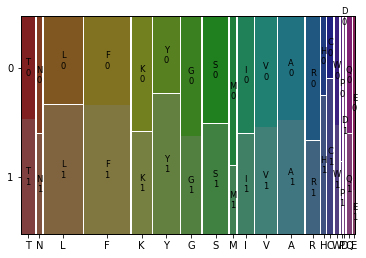

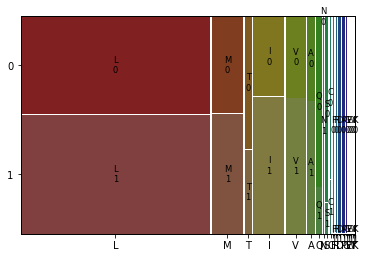

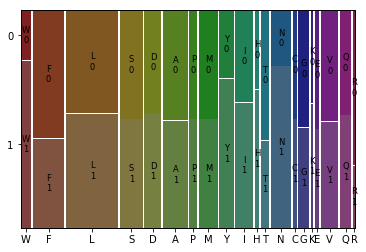

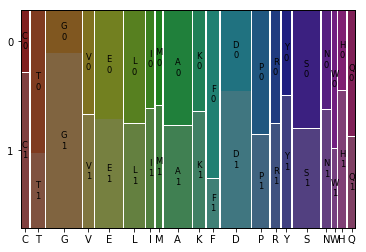

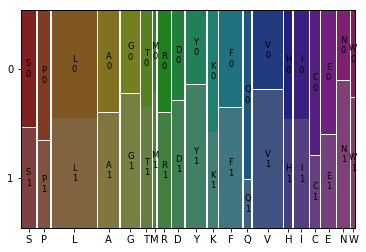

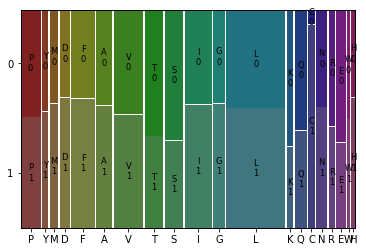

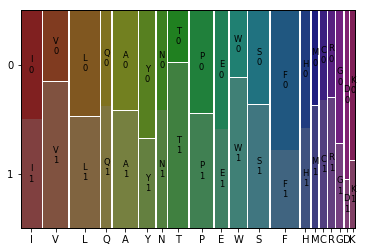

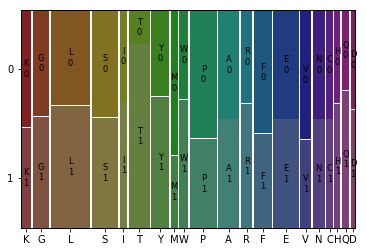

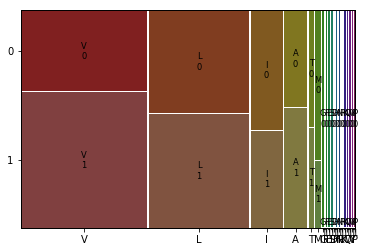

In [85]:
from statsmodels.graphics.mosaicplot import mosaic
for position in range(0,target_length):
    fig, _ = mosaic(total_df, index=[position, "imm"])

# Motifs for top paths

In [259]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None


def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    
    per_allele_decoy[allele_name] = decoy_df.copy()[decoy_df['length'] == target_length]

In [260]:
decoy_data = per_allele_decoy[ALLELES[0]]
len(decoy_data)

401984

In [261]:
decoy_data['b_score'] = [model_binding.log_probability(peptide) for peptide in decoy_data['peptide'].values]
decoy_data['i_score'] = [model_immunogenic.log_probability(peptide) for peptide in decoy_data['peptide'].values]
decoy_data['diff_score'] =  decoy_data['i_score'] - decoy_data['b_score']

In [262]:
decoy_data

,peptide,length,b_score,i_score,diff_score
10,QYPSESSVL,9,-25.851170,-inf,-inf
14,EQSHRPFLM,9,-29.132689,-32.924101,-3.791412
17,MIRNILLMH,9,-30.733226,-inf,-inf
22,PGTASAAHR,9,-30.090189,-inf,-inf
24,KMFTPPSES,9,-26.834065,-inf,-inf
...,...,...,...,...,...
1999983,ITGTKEGIE,9,-29.963873,-inf,-inf
1999986,KAKRAVQRG,9,-28.786355,-inf,-inf
1999993,SPLGPWLSS,9,-25.010404,-inf,-inf
1999995,ILLLIDIEQ,9,-25.938335,-inf,-inf


In [90]:
count = 400
top = decoy_data.sort_values('diff_score', ascending=False)[:count]
bottom = decoy_data.sort_values('diff_score', ascending=True)[:count]
df = decoy_data.sort_values('diff_score', ascending=True)
bottom_not_inf = df[~np.isinf(df['diff_score'])][:count]

In [91]:
top.head(10)

,peptide,length,b_score,i_score,diff_score
59367,RAILKDPPV,9,-24.956221,-19.374003,5.582218
100847,RALNGFTPL,9,-24.431453,-19.379671,5.051782
187364,CMNRCCNAT,9,-33.784584,-29.251608,4.532976
23336,LMICVEWWA,9,-29.339227,-24.845510,4.493717
172811,CCNMFQAGL,9,-32.030409,-28.063061,3.967348
56292,CMLCLGQST,9,-29.690291,-25.840860,3.849431
47472,YVLMVCCKL,9,-27.798635,-24.112146,3.686489
172829,FLCAACGEI,9,-27.293936,-23.638786,3.655150
7884,FCDCCHSYA,9,-33.542534,-29.917136,3.625399
139950,LMFLMLGCA,9,-29.175571,-25.561444,3.614127


In [92]:
top[['peptide', 'b_score']]

,peptide,b_score
59367,RAILKDPPV,-24.956221
100847,RALNGFTPL,-24.431453
187364,CMNRCCNAT,-33.784584
23336,LMICVEWWA,-29.339227
172811,CCNMFQAGL,-32.030409
...,...,...
197231,ILFMCVRHA,-27.267608
174616,LTPPCARWA,-30.384838
118413,WCSCPHQPL,-32.775067
152304,QMGGLSMLL,-24.693995


In [93]:
top[['peptide', 'i_score']]

,peptide,i_score
59367,RAILKDPPV,-19.374003
100847,RALNGFTPL,-19.379671
187364,CMNRCCNAT,-29.251608
23336,LMICVEWWA,-24.845510
172811,CCNMFQAGL,-28.063061
...,...,...
197231,ILFMCVRHA,-26.066443
174616,LTPPCARWA,-29.185563
118413,WCSCPHQPL,-31.580478
152304,QMGGLSMLL,-23.499991


In [94]:
bottom.head(10)

,peptide,length,b_score,i_score,diff_score
2,LPPGDRDKL,9,-25.386600,-inf,-inf
126084,EPDYNYEFA,9,-30.123892,-inf,-inf
126070,WEQGCRKDN,9,-35.041432,-inf,-inf
126069,KGHQLDGTR,9,-28.920965,-inf,-inf
126065,AVFMKYAEN,9,-30.061425,-inf,-inf
126059,PPAGDARLL,9,-25.800804,-inf,-inf
126058,LSCLSSHLQ,9,-28.928924,-inf,-inf
126047,KNYQPAAHS,9,-29.639578,-inf,-inf
126044,FQTGQNDYK,9,-30.286345,-inf,-inf
126042,ASNRPLEPP,9,-27.093737,-inf,-inf


In [95]:
bottom_not_inf

,peptide,length,b_score,i_score,diff_score
124509,SSKQKRKKT,9,-28.324110,-37.044912,-8.720802
100373,ENRTPEKTM,9,-30.793433,-39.204366,-8.410933
112977,RSRPSRGGT,9,-26.950124,-35.347734,-8.397610
130934,PSKTTDDKT,9,-31.622763,-39.967467,-8.344705
164718,EARFLAGVM,9,-28.451928,-36.697641,-8.245713
...,...,...,...,...,...
108461,IQTDILKQA,9,-24.190100,-28.842190,-4.652090
146206,DATLQHVLM,9,-28.955280,-33.601414,-4.646134
5324,EASPAPLVL,9,-23.749381,-28.393433,-4.644052
67553,DNGPQQPST,9,-29.724702,-34.367247,-4.642545


In [203]:
import logomaker


def make_logo(df):
    peptides = df['peptide'].values
    matrix = logomaker.alignment_to_matrix(peptides)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    result = ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',color_scheme='chemistry')
    return result

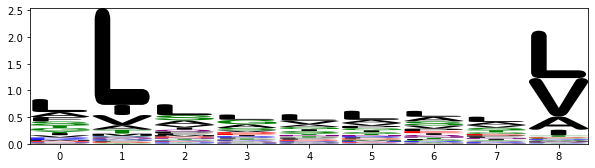

In [204]:
make_logo(top)

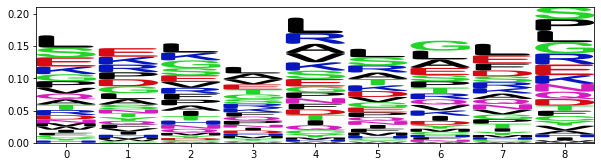

In [98]:
make_logo(bottom)

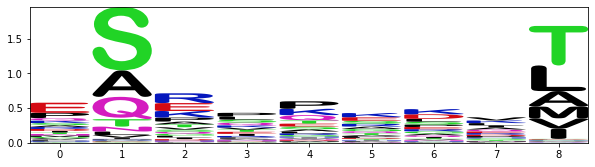

In [99]:
make_logo(bottom_not_inf)

# Top binders. Same analysis

In [263]:
top_percent_binding_value = np.percentile(decoy_data['b_score'].values, 98)
top_percent_binding_value

-22.914692870368693

In [264]:
len(decoy_data[decoy_data['b_score'] > top_percent_binding_value])

8040

In [272]:
selected_decoy_data = decoy_data[decoy_data['b_score'] > top_percent_binding_value].copy()

In [273]:
count = 300
top = selected_decoy_data.sort_values('diff_score', ascending=False)[:count]
bottom = selected_decoy_data.sort_values('diff_score', ascending=True)[:count]
df = selected_decoy_data.sort_values('diff_score', ascending=True)
bottom_not_inf = df[~np.isinf(df['diff_score'])][:count]

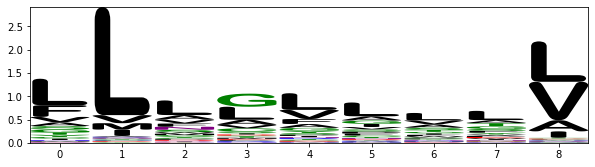

In [274]:
make_logo(top)

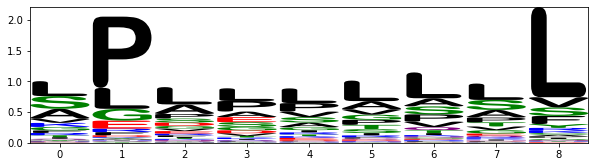

In [275]:
make_logo(bottom)

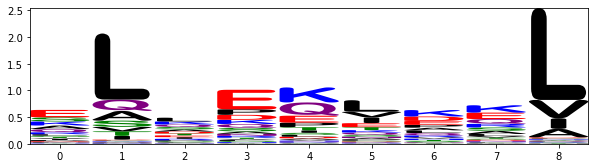

In [276]:
make_logo(bottom_not_inf)

## Same for training data

In [230]:
train_df_repr_db = pivot_data_dict['Train']['db']['mb']
train_df_repr_di = pivot_data_dict['Train']['di']['mb']

In [231]:


train_df_repr_db['b_score'] =  [model_binding.log_probability(peptide) for peptide in train_df_repr_db.index.values]
train_df_repr_di['b_score'] =  [model_binding.log_probability(peptide) for peptide in train_df_repr_di.index.values]

train_df_repr_db['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in train_df_repr_db.index.values]
train_df_repr_di['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in train_df_repr_di.index.values]

train_df_repr_db['peptide'] = train_df_repr_db.index.values
train_df_repr_di['peptide'] = train_df_repr_di.index.values

In [232]:
train_df_repr_db['diff_score'] =  train_df_repr_db['i_score'] - train_df_repr_db['b_score']
train_df_repr_db

path_index,0,1,2,3,4,5,6,7,8,9,...,34,35,36,37,b_score,i_score,peptide,diff_score,i_score_corrected,b_score_corrected
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGWQTL,-39.109073,-48.370801,-41.520572,-34.273045,-39.429917,-48.691645,-25.296135,-34.557863,-42.848265,-52.109993,...,-42.811954,-52.073682,-28.678172,-37.939900,-24.748345,-26.079367,AAAAGWQTL,-1.331022,-27.871126,-28.385931
AAAAKVPEV,-29.395915,-37.704552,-31.634706,-23.434089,-29.853141,-38.161779,-24.090935,-32.399573,-33.135106,-41.443744,...,-33.235178,-41.543816,-27.472972,-35.781610,-21.433836,-24.123069,AAAAKVPEV,-2.689233,-25.914829,-25.071422
AAAANPLAL,-29.009000,-38.270728,-32.438773,-25.191246,-29.944787,-39.206515,-22.707026,-31.968754,-32.748192,-42.009920,...,-33.326824,-42.588552,-26.089063,-35.350791,-22.219589,-23.890386,AAAANPLAL,-1.670797,-25.682145,-25.857175
AAAATCALV,-72.999530,-81.308168,-75.830726,-67.630109,-73.143561,-81.452199,-26.579190,-34.887828,-76.738722,-85.047360,...,-76.525598,-84.834235,-29.961227,-38.269865,-24.410200,-23.996122,AAAATCALV,0.414078,-25.787881,-28.047786
AAAAVIPTV,-30.158578,-38.467216,-32.706459,-24.505842,-30.615804,-38.924442,-23.424201,-31.732839,-33.897769,-42.206407,...,-33.997841,-42.306479,-26.806238,-35.114876,-21.491467,-21.919268,AAAAVIPTV,-0.427800,-23.711027,-25.129053
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYQNYFEKL,-61.376046,-70.637774,-63.139380,-55.891853,-61.451112,-70.712840,-29.095887,-38.357615,-66.378908,-75.640636,...,-66.345145,-75.606873,-33.989920,-43.251648,-27.590362,-inf,YYQNYFEKL,-inf,-inf,-31.227948
YYQSGLSIV,-38.752118,-47.060756,-43.127804,-34.927187,-39.731731,-48.040369,-26.042234,-34.350872,-43.754980,-52.063618,...,-44.625764,-52.934402,-30.936267,-39.244905,-25.773144,-inf,YYQSGLSIV,-inf,-inf,-29.410730
YYRPLHDEY,-35.780264,-61.202462,-38.080330,-46.993273,-36.298765,-61.720963,-27.845529,-53.267727,-42.682955,-68.105153,...,-41.192798,-66.614996,-32.739561,-58.161760,-27.835719,-inf,YYRPLHDEY,-inf,-inf,-31.473305


In [233]:
train_df_repr_db[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
AAAAGWQTL,-24.748345,-26.079367,-1.331022
AAAAKVPEV,-21.433836,-24.123069,-2.689233
AAAANPLAL,-22.219589,-23.890386,-1.670797
AAAATCALV,-24.410200,-23.996122,0.414078
AAAAVIPTV,-21.491467,-21.919268,-0.427800
AAADFTAKV,-22.076556,-23.802430,-1.725874
AAADKIPGL,-21.500061,-24.412558,-2.912497
AAAESLLKA,-21.983516,-24.666262,-2.682746
AAAESSTSL,-21.614631,-24.128600,-2.513969


In [234]:
top_500 = train_df_repr_db.sort_values('diff_score', ascending=False)[:500]
bottom_500 = train_df_repr_db.sort_values('diff_score', ascending=True)[:500]
df = train_df_repr_db.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

In [235]:
bottom_500[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
YYTKGFALL,-25.731672,-inf,-inf
RPGGPSNVL,-23.833625,-inf,-inf
RPGLAEYIE,-28.211932,-inf,-inf
RPHAFQVIL,-25.636745,-inf,-inf
RPHTVLTVI,-25.734584,-inf,-inf
RPIILLDSL,-23.002210,-inf,-inf
RPIQNVPGP,-26.939758,-inf,-inf
RPISGQKEV,-25.525410,-inf,-inf
RPITDSPVL,-24.044733,-inf,-inf


In [236]:
bottom_500_not_inf[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
KSRKPKKGA,-27.086598,-35.006855,-7.920257
SSRLPGTSL,-22.588755,-29.543174,-6.954418
QSIVQAKPL,-26.320095,-32.696608,-6.376514
ESREKLTEL,-24.955481,-31.297353,-6.341872
IAIIPSKKL,-24.484140,-30.484516,-6.000376
KSRNTTPMM,-29.176579,-35.146597,-5.970017
TSPSPSKSI,-25.726230,-31.670741,-5.944511
RSGVPPKVV,-25.610468,-31.378220,-5.767751
AQQIQKVVM,-27.698376,-33.389990,-5.691614


In [237]:
top_500[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
FANYNFTLV,-25.939340,-13.286928,12.652413
FANHNFTLV,-25.715615,-13.104782,12.610833
FANCNFTLV,-26.751849,-14.203107,12.548742
FVNYNFTLV,-25.362871,-13.437308,11.925563
IANYNFTLV,-26.283546,-14.601249,11.682297
FANHKFTLV,-25.170394,-13.668581,11.501813
FVNYDFTIV,-26.565311,-15.624063,10.941248
FANSKFTLV,-23.872093,-13.099747,10.772346
YIIIGDSPV,-25.414421,-15.359238,10.055182


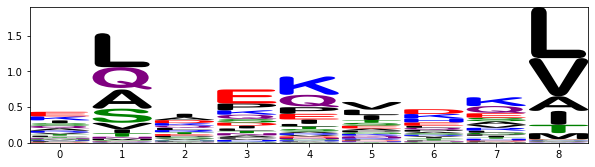

In [238]:
make_logo(bottom_500_not_inf)

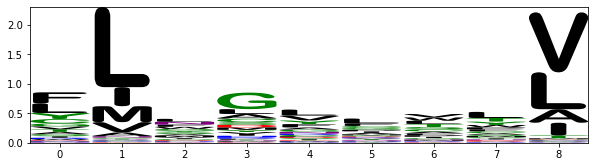

In [244]:
make_logo(top_500)

In [245]:
i_complexity = len(df_i_paths)
b_complexity = len(df_b_paths)

In [246]:
train_df_repr_db['i_score_corrected'] = train_df_repr_db['i_score'] - np.log(i_complexity)
train_df_repr_db['b_score_corrected'] = train_df_repr_db['b_score'] - np.log(b_complexity)
train_df_repr_db['diff_score'] = train_df_repr_db['i_score_corrected'] - train_df_repr_db['b_score_corrected']

In [247]:
top_500 = train_df_repr_db.sort_values('diff_score', ascending=False)[:500]
bottom_500 = train_df_repr_db.sort_values('diff_score', ascending=True)[:500]
df = train_df_repr_db.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

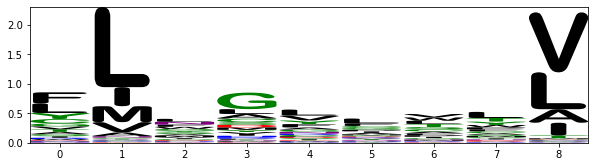

In [248]:
make_logo(top_500)

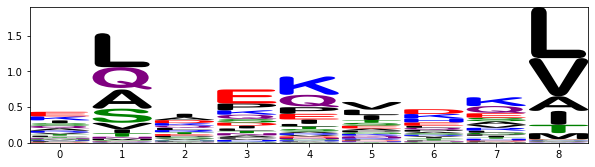

In [249]:
make_logo(bottom_500_not_inf)

In [250]:
top_500

path_index,0,1,2,3,4,5,6,7,8,9,...,34,35,36,37,b_score,i_score,peptide,diff_score,i_score_corrected,b_score_corrected
peptide,,,,,,,,,,,,,,,,,,,,,
FANYNFTLV,-32.992854,-41.301492,-36.312875,-28.112258,-33.625709,-41.934347,-26.786628,-35.095266,-36.863567,-45.172205,...,-37.007746,-45.316384,-30.168665,-38.477303,-25.939340,-13.286928,FANYNFTLV,14.498239,-15.078687,-29.576927
FANHNFTLV,-33.499287,-41.807925,-36.819308,-28.618691,-34.132142,-42.440780,-27.293061,-35.601699,-37.370000,-45.678638,...,-37.514179,-45.822817,-30.675098,-38.983736,-25.715615,-13.104782,FANHNFTLV,14.456660,-14.896542,-29.353201
FANCNFTLV,-34.306008,-42.614646,-37.626029,-29.425412,-34.938863,-43.247501,-28.099782,-36.408420,-38.176721,-46.485358,...,-38.320900,-46.629538,-31.481819,-39.790457,-26.751849,-14.203107,FANCNFTLV,14.394569,-15.994866,-30.389435
FVNYNFTLV,-33.532681,-41.841319,-36.852702,-28.652085,-34.165536,-42.474174,-27.326455,-35.635093,-35.698239,-44.006877,...,-35.842419,-44.151056,-29.003338,-37.311975,-25.362871,-13.437308,FVNYNFTLV,13.771389,-15.229068,-29.000457
IANYNFTLV,-33.337059,-41.645697,-36.657080,-28.456463,-33.969915,-42.278552,-27.130834,-35.439471,-37.207772,-45.516410,...,-37.351951,-45.660589,-30.512870,-38.821508,-26.283546,-14.601249,IANYNFTLV,13.528124,-16.393008,-29.921132
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GLFLSLGLV,-75.093470,-83.402108,-79.685748,-71.485131,-76.998583,-85.307220,-28.117968,-36.426606,-71.345158,-79.653796,...,-73.053814,-81.362452,-24.173200,-32.481838,-22.084055,-20.193642,GLFLSLGLV,3.736239,-21.985402,-25.721641
TLMGHMLYL,-37.992643,-47.254371,-40.193439,-32.945912,-38.928430,-48.190158,-32.741777,-42.003505,-34.031811,-43.293538,...,-34.983662,-44.245389,-28.797009,-38.058737,-22.840770,-20.950702,TLMGHMLYL,3.735894,-22.742462,-26.478356
FLIVSLCPT,-78.857222,-89.167164,-82.202348,-76.003035,-78.898626,-89.208568,-31.881720,-42.191662,-75.168731,-85.478673,...,-74.953858,-85.263800,-27.936952,-38.246894,-26.249322,-24.364406,FLIVSLCPT,3.730742,-26.156166,-29.886908


## Decoy corrected scores

In [363]:
len(decoy_data)

401984

In [278]:
decoy_data['i_score_corrected'] = decoy_data['i_score'] - np.log(i_complexity)
decoy_data['b_score_corrected'] = decoy_data['b_score'] - np.log(b_complexity)
decoy_data['diff_score'] = decoy_data['i_score_corrected'] - decoy_data['b_score_corrected']

In [279]:
sorted_decoy = decoy_data.sort_values('i_score_corrected', ascending=False)

## Difference acros binders

In [338]:
top_percent_binding_value = np.percentile(sorted_decoy['b_score_corrected'].values, 98)
top_percent_binding_value

-26.55227903009508

In [339]:
selected_decoy = sorted_decoy[sorted_decoy['b_score_corrected'] > top_percent_binding_value]

top_500 = selected_decoy.sort_values('diff_score', ascending=False)[:400].copy()
bottom_500 = selected_decoy.sort_values('diff_score', ascending=True)[:400]
df = selected_decoy.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:400].copy()

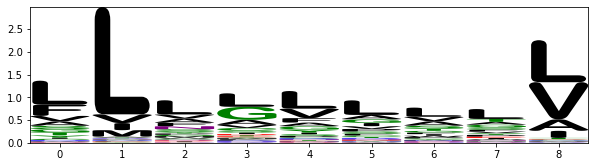

In [340]:
make_logo(top_500)

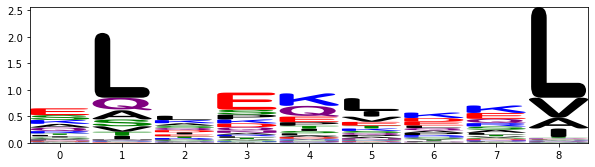

In [341]:
make_logo(bottom_500_not_inf)

## Binding across binders

In [360]:
top_500 = selected_decoy.sort_values('b_score_corrected', ascending=False)[:500]
bottom_500 = selected_decoy.sort_values('b_score_corrected', ascending=True)[:500]
df = selected_decoy.sort_values('b_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['b_score_corrected'])][:500]

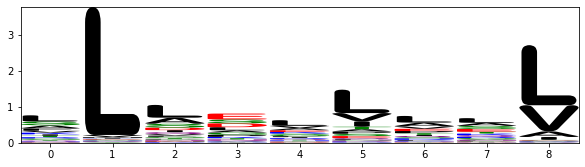

In [361]:
make_logo(top_500)

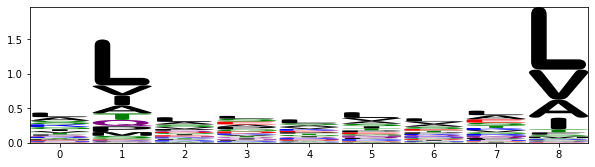

In [362]:
make_logo(bottom_500_not_inf)

## Immunogenicity acros binders

In [364]:
top_500 = selected_decoy.sort_values('i_score_corrected', ascending=False)[:500]
bottom_500 = selected_decoy.sort_values('i_score_corrected', ascending=True)[:500]
df = selected_decoy.sort_values('i_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score_corrected'])][:500]

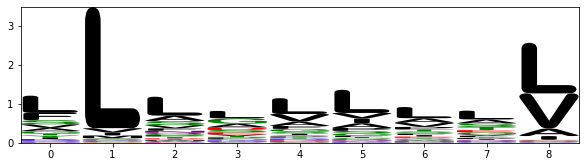

In [365]:
make_logo(top_500)

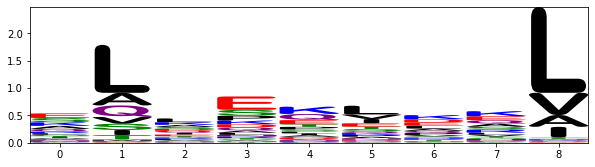

In [366]:
make_logo(bottom_500_not_inf)

## Binding score  across all peptides

In [351]:
top_500 = sorted_decoy.sort_values('b_score_corrected', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('b_score_corrected', ascending=True)[:500]
df = sorted_decoy.sort_values('b_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['b_score_corrected'])][:500]

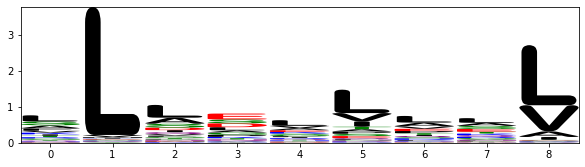

In [352]:
make_logo(top_500)

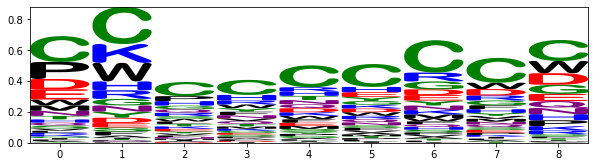

In [353]:
make_logo(bottom_500_not_inf)

## Immunogenicity score across all peptides

In [354]:
top_500 = sorted_decoy.sort_values('i_score_corrected', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('i_score_corrected', ascending=True)[:500]
df = sorted_decoy.sort_values('i_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score_corrected'])][:500]

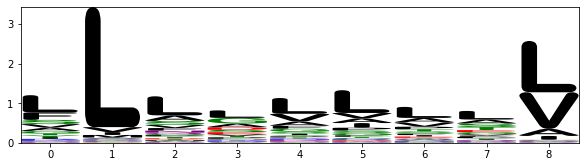

In [355]:
make_logo(top_500)

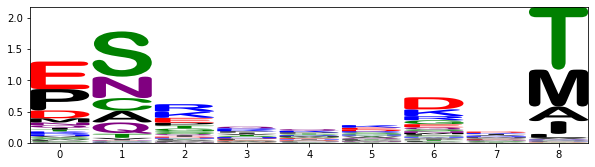

In [356]:
make_logo(bottom_500_not_inf)

## Difference across all peptides

In [357]:
top_500 = sorted_decoy.sort_values('diff_score', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('diff_score', ascending=True)[:500]
df = sorted_decoy.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

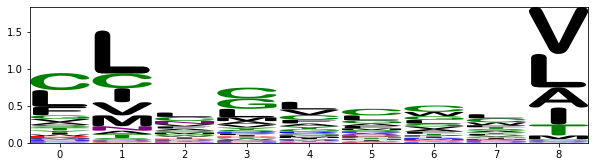

In [358]:
make_logo(top_500)

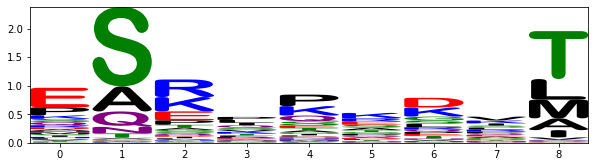

In [359]:
make_logo(bottom_500_not_inf)

## 1000 by 1000 sorted

In [ ]:
sorted_df = train_df_repr_db.sort_values('diff_score', ascending=False)
size=1000
times = int(len(sorted_df) /size )

In [ ]:
for i in range(0,times, 2):
    print(i*size, (i+1)*size)
    target_df = sorted_df[i*size: (i+1)*size]
    make_logo(target_df)
    

In [ ]:
sorted_df = train_df_repr_db.sort_values('i_score', ascending=False)
size=1000
times = int(len(sorted_df) /size )

In [ ]:
for i in range(0,times, 2):
    print(i*size, (i+1)*size)
    target_df = sorted_df[i*size: (i+1)*size]
    make_logo(target_df)
    

In [ ]:
train_df_repr_db

In [ ]:
make_logo(pd.DataFrame({"peptide":train_peptides_immunogenic}))

In [ ]:
make_logo(pd.DataFrame({"peptide":train_peptides_non_immunogenic}))

In [ ]:
make_logo(pd.DataFrame({"peptide":train_peptides_binding}))

In [ ]:
make_logo(pd.DataFrame({"peptide":train_peptides_non_binding}))

In [ ]:
decoy_data

In [ ]:
decoy_sorted = decoy_data.sort_values('b_score', ascending=False)

In [ ]:
make_logo(decoy_sorted[:4000])

In [ ]:
decoy_sorted = decoy_data.sort_values('i_score', ascending=False)

In [ ]:
make_logo(decoy_sorted[:50])